# IND320 Dashboard – del 4

Denne notebooken dokumenterer del 4 av IND320-prosjektet: valutakurser fra Norges Bank, tidssoner i datakildene, prognose av fyllingsgraden med River, og omstrukturering av Streamlit-appen med nye sider.

## Lenker
- GitHub-repository: https://github.com/Kaja321/ind320-dashboard-kaja321
- Publisert Streamlit-app: https://ind320-dashboard-kaja321.streamlit.app/
- Screencast: (legges inn til slutt)

## Bruk av kunstig intelligens
Jeg har brukt Claude (Anthropic) som støtte gjennom hele del 4. KI ble brukt til å:
- gå gjennom oppgaven og lage en plan for rekkefølgen på arbeidet
- foreslå og forbedre kode for valutakurser, tidssoner, GeoJSON, kartet, korrelasjonen og prognosen med River
- hjelpe til med å gjøre om de statiske plottene (matplotlib) til interaktive plott (Plotly), og med å lage den nye menyen med grupper (st.navigation)
- feilsøke feilmeldinger, både i Python og i git
- foreslå formuleringer til kommentarer, markdown-tekst og README

Jeg har selv kjørt og testet all kode, vurdert og tilpasset forslagene, og tatt valgene underveis, for eksempel grupperingen av sidene, fargene og hvordan plottene skulle se ut. Jeg har spurt om forklaringer når jeg ikke forsto koden eller resultatene, slik at jeg kan stå for det som er levert.

## Prosjektlogg

### Oppstart og notebook
Etter tilbakemeldingene på del 3 laget jeg en README, og alt nytt arbeid ble gjort på branchen part4. Først skrev jeg en funksjon som henter euro- og dollarkurser fra Norges Bank. Deretter undersøkte jeg tidssonene i datakildene. NVE og Norges Bank oppgir bare dato, mens ENTSO-E og open-meteo bruker UTC. Tidssonen forsvant når ENTSO-E-dataene ble lest fra MongoDB, og open-meteo oppga feil forskyvning for sommertid. Jeg valgte derfor å holde timesdata i UTC og regne om til norsk tid før de slås sammen til uker som slutter på søndag, slik som i magasinstatistikken. Shapefilene ble gjort om til forenklede GeoJSON-filer, og jeg tegnet en skisse av appen før jeg endret koden.

### Omskriving av appen
Sidene ble gruppert i Overview, Analysis og Prediction med st.navigation, med ikoner i menyen. Jeg valgte et blått tema og en felles fargeliste, så alle plottene ser like ut. Alle matplotlib-plott ble byttet med Plotly. På Power exchange viste jeg nettoflyten i stedet for to linjer som hele tiden hoppet ned til null.

### Kart og korrelasjon
Kartet viser pris- eller vassdragsområdene fargelagt etter fyllingsgrad eller vær for valgt uke. Et klikk lagres i session_state, så de andre sidene bruker det valgte området. Først fulgte ikke kartet valget i sidebaren for VASS og NO, så jeg lot kartet bytte områdetype etter valget der.

Uka i kartet er synkronisert med prognosen. Først hoppet slideren tilbake når jeg dro i den, fordi startverdien ble satt med value fra session_state. Jeg løste det ved å gi slideren en egen key og lagre valget med on_change.

Etter at korrelasjonssiden var ferdig, prøvde jeg ulike innstillinger for NO3 i 2021–2024. Nedbør hadde en svak positiv korrelasjon med den ukentlige endringen i fyllingsgraden samme uke (0,19), men sammenhengen forsvant etter to uker. Den var sterkest om høsten, da nedbøren kommer som regn. Snøfall hadde en negativ korrelasjon samme uke (−0,35), men med 16 ukers forsinkelse ble den positiv (0,39), fordi snøen smelter om våren. Sammenhengen endrer seg altså gjennom året, og det passet med at været forbedret prognosen mest om våren.

### Prognose
Prognosen bruker SNARIMAX fra River med ukentlige data, som passer med magasinstatistikken og gjør modellen rask. Den første modellen bygde på fjorårets verdier og spådde over 100 % om våren. Den beste modellen spår i stedet den ukentlige endringen, med nedbør, snø og temperatur som eksogene variabler. Den bommet med 8,1 prosentpoeng i snitt, mot 18,7 for «samme uke i fjor». Valutakursen gjorde prognosen dårligere. I appen brukes normalt vær for uker uten værdata, og MAE ble 11,7, fordi appen bruker færre år og punkter på grunn av grensen hos open-meteo.

### Bonus og læring
Som bonusoppgave valgte jeg «Waiting time». Alle nedlastinger fra NVE, open-meteo, Norges Bank og MongoDB caches med st.cache_data eller st.cache_resource, og det som tar tid, viser en spinner. Underveis lærte jeg å sjekke dataene før jeg slår dem sammen. Da ingen valuta var valgt i prognosen, var valutatabellen tom, og da den ble slått sammen med de andre dataene, forsvant datoene fra tabellen.

# Dataanalyse

## Valutakurser fra Norges Bank

Norges Bank har et åpent API for valutakurser. Adressen bygges slik:
`https://data.norges-bank.no/api/data/EXR/B.EUR+USD.NOK.SP`

- `EXR` er datasettet med valutakurser
- `B` betyr at kursene er daglige, men bare for virkedager (business days)
- `EUR+USD` er valutaene. Med `+` kan flere hentes i samme forespørsel
- `NOK` betyr at kursen er oppgitt i norske kroner (hvor mange kroner én euro koster)
- `SP` betyr spotkurs

Med `format=csv` kommer svaret som en tabell som pandas kan lese direkte. `locale=en` gir punktum som desimaltegn.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt


def download_exchange_rates(start_date, end_date, currencies=["EUR", "USD"]):
    """Laster ned daglige valutakurser mot norske kroner fra Norges Bank.

    start_date: første dag, f.eks. "2024-01-01"
    end_date:   siste dag, f.eks. "2024-12-31"
    currencies: liste med valutakoder, standard er euro og dollar

    Returnerer en tabell med dato som indeks og én kolonne per valuta (NOK per enhet).
    """
    # Valutakodene settes sammen med +, f.eks. "EUR+USD"
    codes = "+".join(currencies)
    url = (f"https://data.norges-bank.no/api/data/EXR/B.{codes}.NOK.SP"
           f"?format=csv&startPeriod={start_date}&endPeriod={end_date}&locale=en")

    # Norges Bank bruker semikolon mellom kolonnene i CSV-fila
    df = pd.read_csv(url, sep=";")

    # Svaret har én rad per dag og valuta. pivot gjør det om til én kolonne per valuta.
    # TIME_PERIOD er datoen, BASE_CUR er valutaen og OBS_VALUE er kursen.
    rates = df.pivot(index="TIME_PERIOD", columns="BASE_CUR", values="OBS_VALUE")

    # Datoformat på indeksen, og ryddige navn
    rates.index = pd.to_datetime(rates.index)
    rates.index.name = "date"
    rates.columns.name = None
    return rates

Antall dager: 251
          EUR     USD
count  251.00  251.00
mean    11.63   10.74
std      0.19    0.24
min     11.27   10.30
25%     11.45   10.55
50%     11.67   10.69
75%     11.77   10.95
max     12.11   11.42


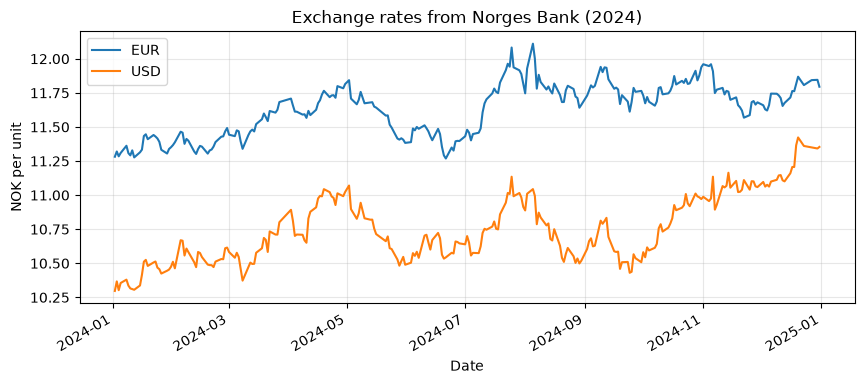

In [2]:
# Tester funksjonen for 2024, samme år som værdataene i del 3
rates = download_exchange_rates("2024-01-01", "2024-12-31")
print("Antall dager:", len(rates))   # rundt 250, fordi helger og helligdager mangler
print(rates.describe().round(2))

# Plotter begge kursene i samme figur
fig, ax = plt.subplots(figsize=(10, 4))
rates.plot(ax=ax)
ax.set_title("Exchange rates from Norges Bank (2024)")
ax.set_xlabel("Date")
ax.set_ylabel("NOK per unit")
ax.grid(alpha=0.3)
plt.show()

Funksjonen virker: den henter 251 dager for 2024, med kurser for både euro og dollar. Det er bare virkedager, fordi Norges Bank ikke publiserer kurser i helger og på helligdager. Når kursene skal brukes sammen med magasinstatistikken, som er ukentlig, må de derfor gjøres om til samme tidsoppløsning, for eksempel gjennomsnitt per uke.

## Tidssoner i datakildene

Datakildene oppgir tid på ulike måter. Noen bruker UTC, noen bruker norsk tid, og noen oppgir bare dato uten klokkeslett. Hvis dataene kobles sammen uten å ta hensyn til dette, kan verdier havne på feil time eller feil dag. Norsk tid er UTC+1 om vinteren og UTC+2 om sommeren (sommertid), så forskjellen er én eller to timer. Ved overgangen til sommertid mangler én time, og ved overgangen til vintertid kommer én time to ganger.

Under sjekkes hver kilde for seg.

In [3]:
import requests

# Henter magasinstatistikken (trengs også senere til prognosen)
url = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"
reservoirs = pd.DataFrame(requests.get(url).json())

# Viser datoen slik den kommer fra APIet, før den gjøres om
print("Rå verdi fra APIet:", reservoirs["dato_Id"].iloc[0])

reservoirs["dato_Id"] = pd.to_datetime(reservoirs["dato_Id"])
reservoirs["area"] = reservoirs["omrType"] + " " + reservoirs["omrnr"].astype(str)
print("Tidssone:", reservoirs["dato_Id"].dt.tz)   # None betyr at ingen tidssone er oppgitt

# Hvilken ukedag datoene faller på
print(reservoirs["dato_Id"].dt.day_name().value_counts())
reservoirs[["dato_Id", "iso_aar", "iso_uke"]].head()

Rå verdi fra APIet: 2020-11-15
Tidssone: None
dato_Id
Sunday    14967
Name: count, dtype: int64


,dato_Id,iso_aar,iso_uke
0,2020-11-15,2020,46
1,2011-08-28,2011,34
2,1998-07-05,1998,27
3,2011-03-27,2011,12
4,2017-11-05,2017,44


In [4]:
import tomllib
import pymongo
import dns.resolver

# Ruteren svarte ikke på DNS-oppslaget for MongoDB Atlas (mongodb+srv krever et ekstra oppslag),
# så vi bruker Google (8.8.8.8) og Cloudflare (1.1.1.1) sine DNS-servere i stedet
dns.resolver.default_resolver = dns.resolver.Resolver(configure=False)
dns.resolver.default_resolver.nameservers = ["8.8.8.8", "1.1.1.1"]

# Leser MongoDB-adressen fra secrets.toml, så adressen ikke står i notebooken
with open("../.streamlit/secrets.toml", "rb") as f:
    secrets = tomllib.load(f)
client = pymongo.MongoClient(secrets["mongo"]["uri"])

# Henter bare noen få rader, det holder for å se tidsformatet
flows = pd.DataFrame(list(client["ind320"]["flows"].find({}, {"_id": 0}).limit(5)))
print(flows.dtypes)
flows.head()

connection               str
direction                str
time          datetime64[us]
flow_mw              float64
dtype: object


,connection,direction,time,flow_mw
0,NO_2-DE_LU,export,2024-10-14 22:00:00,1352.48
1,NO_2-DE_LU,export,2024-10-14 23:00:00,1271.00
2,NO_2-DE_LU,export,2024-10-15 09:00:00,1049.28
3,NO_2-DE_LU,export,2024-10-15 13:00:00,1404.00
4,NO_2-DE_LU,export,2024-10-15 15:00:00,1404.84


In [5]:
import openmeteo_requests

# Klienten sender forespørsler til open-meteo (som i download_weather, men uten cache og retry,
# fordi vi bare henter litt data for å se på tidsformatet)
openmeteo = openmeteo_requests.Client()
# Ett punkt i Oslo og én dag er nok. 1. juli er sommertid, så forskjellen mellom
# UTC og norsk tid er 2 timer og lett å se.
params = {"latitude": 59.91, "longitude": 10.75,   # Oslo
          "start_date": "2024-07-01", "end_date": "2024-07-01",
          "hourly": "temperature_2m", "models": "era5"}

# Uten timezone-parameter (slik funksjonen i del 3 gjør det)
response = openmeteo.weather_api("https://archive-api.open-meteo.com/v1/archive", params=params)[0]
print("Standard:     ", response.Timezone(), "– forskyvning", response.UtcOffsetSeconds() / 3600, "timer")

# Med norsk tidssone
params["timezone"] = "Europe/Oslo"
response = openmeteo.weather_api("https://archive-api.open-meteo.com/v1/archive", params=params)[0]
print("Europe/Oslo:  ", response.Timezone(), "– forskyvning", response.UtcOffsetSeconds() / 3600, "timer")

Standard:      None – forskyvning 0.0 timer
Europe/Oslo:   b'Europe/Oslo' – forskyvning 1.0 timer


In [6]:
# MongoDB gir tidene uten tidssone. tz_localize sier at de er i UTC,
# og tz_convert regner dem om til norsk tid (med sommertid).
flows["time_utc"] = flows["time"].dt.tz_localize("UTC")
flows["time_oslo"] = flows["time_utc"].dt.tz_convert("Europe/Oslo")
flows[["time_utc", "time_oslo"]].head()

,time_utc,time_oslo
0,2024-10-14 22:00:00+00:00,2024-10-15 00:00:00+02:00
1,2024-10-14 23:00:00+00:00,2024-10-15 01:00:00+02:00
2,2024-10-15 09:00:00+00:00,2024-10-15 11:00:00+02:00
3,2024-10-15 13:00:00+00:00,2024-10-15 15:00:00+02:00
4,2024-10-15 15:00:00+00:00,2024-10-15 17:00:00+02:00


In [7]:
# rates ble lastet ned over. Sjekker tidssone og ukedager.
print("Tidssone:", rates.index.tz)
print(rates.index.day_name().value_counts())

Tidssone: None
date
Tuesday      52
Wednesday    50
Friday       50
Monday       50
Thursday     49
Name: count, dtype: int64


### Funn og løsning

**Magasinstatistikk (NVE)** har ukentlige verdier med bare dato og ingen tidssone. Datoen er alltid en søndag, altså siste dag i uka.

**ENTSO-E** har timesverdier i UTC. Dataene starter 14. oktober 2024 kl. 22:00, som er midnatt 15. oktober norsk tid. Når dataene leses fra MongoDB, forsvinner tidssonen, så den må settes tilbake med `tz_localize("UTC")`.

**open-meteo** gir timesverdier i UTC hvis man ikke velger noe annet. Med `timezone="Europe/Oslo"` ble forskyvningen oppgitt som 1 time for 1. juli, selv om det var sommertid (2 timer). Det er tryggere å hente dataene i UTC og regne om selv.

**Norges Bank** har bare dato, ingen tidssone, og bare virkedager. Kursene publiseres rundt kl. 16 norsk tid.

**Løsning:** Timesdata holdes i UTC, så sommertid ikke lager timer som mangler eller kommer to ganger. Når timesdata skal kobles med NVE eller Norges Bank, regnes tidene først om til norsk tid med `tz_convert("Europe/Oslo")`. Deretter brukes gjennomsnittet for hver uke som slutter på søndag (`resample("W-SUN")`), så ukene passer med magasinstatistikken. Det løser også at valutakursene mangler helger.

## Områdene som GeoJSON

Shapefilene fra del 3 gjøres om til GeoJSON, slik at kartet i appen kan bruke dem uten geopandas. Kantene forenkles for å gjøre filene mindre og kartet raskere, og koordinatene gjøres om til lengde- og breddegrad, som GeoJSON bruker.

In [8]:
import os
import geopandas as gpd

# Leser shapefilene, som i del 3
regions = gpd.read_file("../data/NVE_Region/NVE_Region.shp", encoding="utf-8")
bid_zones = gpd.read_file("../data/Budomrader/Budomrader.shp")

# Vassdragsområdene: NVE-regionene slås sammen (RS + RØ = VASS 1, RV = VASS 2, RM + RN = VASS 3)
region_to_area = {"RS": "VASS 1", "RØ": "VASS 1",
                  "RV": "VASS 2",
                  "RM": "VASS 3", "RN": "VASS 3"}
regions["area"] = regions["REGION"].map(region_to_area)
vass_areas = regions.dissolve(by="area").reset_index()[["area", "geometry"]]

# Strømprisområdene: "NO 1" blir "EL 1", så navnene passer med magasinstatistikken
bid_zones["area"] = bid_zones["budomr"].str.replace("NO", "EL")
el_areas = bid_zones[["area", "geometry"]]

# Lagrer hver områdetype som en egen GeoJSON-fil
for name, areas in [("price_areas", el_areas), ("water_areas", vass_areas)]:
    areas = areas.copy()
    # Forenkler kantene. 1000 er i meter, fordi dataene fortsatt er i UTM33.
    areas["geometry"] = areas.simplify(1000)
    # Gjør om til lengde- og breddegrad, som GeoJSON og Plotly bruker
    areas = areas.to_crs(epsg=4326)
    path = f"../data/{name}.geojson"
    areas.to_file(path, driver="GeoJSON")
    # Viser filstørrelsen, så vi ser at filene ikke er for store
    print(path, round(os.path.getsize(path) / 1e6, 2), "MB")

../data/price_areas.geojson 0.04 MB
../data/water_areas.geojson 0.06 MB


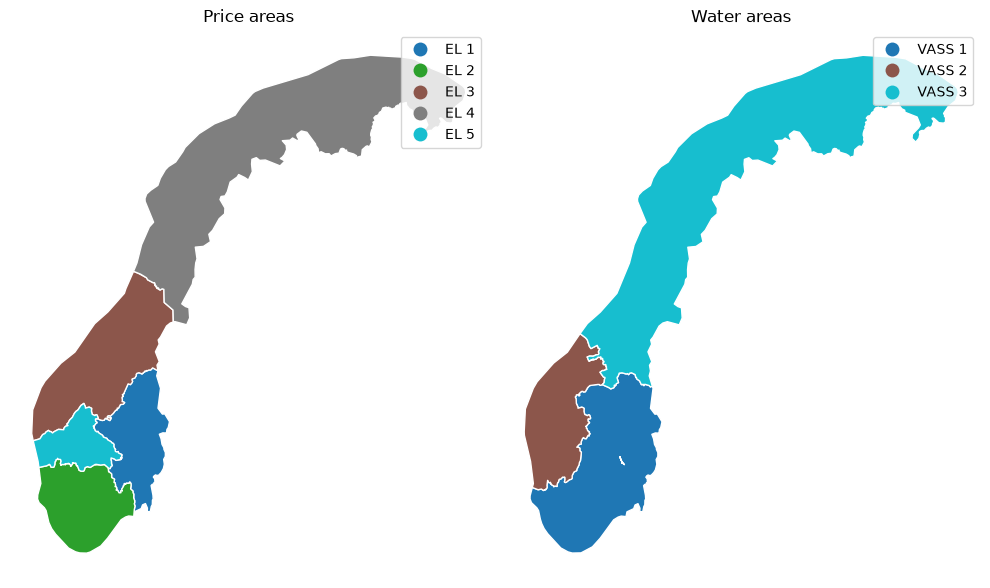

In [9]:
import matplotlib.pyplot as plt

# Leser GeoJSON-filene tilbake og tegner dem, for å sjekke at forenklingen ikke ødela områdene
fig, axs = plt.subplots(1, 2, figsize=(10, 6))
for ax, name in zip(axs, ["price_areas", "water_areas"]):
    areas = gpd.read_file(f"../data/{name}.geojson")
    areas.plot(column="area", ax=ax, legend=True, edgecolor="white", cmap="tab10")
    ax.set_title(name.replace("_", " ").capitalize())
    ax.set_axis_off()
plt.tight_layout()
plt.show()

## Skisse av appen

Før appen ble endret, ble sidene organisert etter type oppgave: oversikt over dataene (Overview), analyse av mønstre og avvik (Analysis), og prognose (Prediction). Home er forsiden. Gruppene vises som overskrifter i menyen.

Området er et felles valg som huskes mellom sidene med `st.session_state`. Tiden som velges i kartet brukes som treningsperiode i prognosen. År og periode velges ellers lokalt på sidene der det gir mer mening.

![App structure](sketch.png)

## Prognose av fyllingsgraden med River

Fyllingsgraden for NO3 (EL 3) spås noen måneder fram med SNARIMAX fra River. Dataene brukes per uke, fordi magasinstatistikken er ukentlig. Det gir 52 punkter per år, som er nok til å se sesongen, og modellen blir rask. Værdataene og valutakursene gjøres om til uker som slutter på søndag (se tidssone-delen), slik at de passer med datoene i magasinstatistikken.

In [10]:
import time
import openmeteo_requests
import requests_cache
from retry_requests import retry

# De tilfeldige punktene fra del 3 (1000 per område)
locations = pd.read_csv("../data/locations.csv")

# Samme oppsett som i del 3: svarene lagres i en cache i No_sync/, så de ikke lastes ned på nytt,
# og forespørsler som feiler, prøves på nytt
cache_session = requests_cache.CachedSession("../No_sync/openmeteo_cache", expire_after=-1)
openmeteo = openmeteo_requests.Client(session=retry(cache_session, retries=5, backoff_factor=0.2))

VARIABLES = ["temperature_2m", "precipitation", "rain", "snowfall",
             "wind_speed_10m", "relative_humidity_2m"]


def download_weather(area, start_date, end_date, n_points=100, batch_size=20, pause=60):
    """Laster ned værdata (ERA5, timesverdier) for et område og en periode (samme som i del 3).

    Returnerer gjennomsnittet over punktene for hver time (tid i UTC).
    """
    points = locations[locations["area"] == area].head(n_points)
    all_points = []
    for start in range(0, len(points), batch_size):
        batch = points.iloc[start:start + batch_size]
        params = {"latitude": batch["latitude"].tolist(), "longitude": batch["longitude"].tolist(),
                  "start_date": start_date, "end_date": end_date,
                  "hourly": VARIABLES, "models": "era5"}
        responses = openmeteo.weather_api("https://archive-api.open-meteo.com/v1/archive", params=params)
        # Ett svar per punkt, gjort om til en tabell med tid og alle variablene
        for response in responses:
            hourly = response.Hourly()
            df = pd.DataFrame({"time": pd.date_range(
                start=pd.to_datetime(hourly.Time(), unit="s", utc=True),
                end=pd.to_datetime(hourly.TimeEnd(), unit="s", utc=True),
                freq=pd.Timedelta(seconds=hourly.Interval()), inclusive="left")})
            for i, variable in enumerate(VARIABLES):
                df[variable] = hourly.Variables(i).ValuesAsNumpy()
            all_points.append(df)
        # Venter før neste porsjon, men ikke etter den siste
        if start + batch_size < len(points):
            print(f"Lastet ned {start + batch_size} av {len(points)} punkter, venter {pause} s ...")
            time.sleep(pause)
    return pd.concat(all_points).groupby("time").mean()

In [11]:
# Nedbør, regn og snø summeres over uka. De andre variablene blir gjennomsnitt.
SUM_VARIABLES = ["precipitation", "rain", "snowfall"]


def to_weekly(hourly):
    """Gjør timesverdier om til uker som slutter på søndag, som i magasinstatistikken."""
    # Fra UTC til norsk tid, så dagene og ukene starter ved norsk midnatt
    hourly = hourly.tz_convert("Europe/Oslo")
    how = {column: ("sum" if column in SUM_VARIABLES else "mean") for column in hourly.columns}
    weekly = hourly.resample("D").agg(how).resample("W-SUN").agg(how)
    weekly.index = weekly.index.tz_localize(None)   # fjerner tidssonen, så datoene kan kobles med NVE
    return weekly.iloc[1:-1]   # første og siste uke er ikke hele, så de fjernes


# 10 år med værdata for NO3. 5 punkter, ett om gangen med 30 s pause, så vi holder oss under
# minuttgrensen hos open-meteo. Tar rundt 2–3 minutter første gang, deretter hentes det fra cachen.
weather_hourly = download_weather("EL 3", "2016-01-01", "2025-12-31", n_points=5, batch_size=1, pause=30)
weather_weekly = to_weekly(weather_hourly)

# Valutakursene som gjennomsnitt per uke (bare virkedager har kurs)
rates_weekly = download_exchange_rates("2016-01-01", "2025-12-31").resample("W-SUN").mean()

# Fyllingsgraden for NO3 i prosent
fill = reservoirs[reservoirs["area"] == "EL 3"].set_index("dato_Id")["fyllingsgrad"] * 100

# Kobler alt på datoen (søndagen uka slutter på). join="inner" beholder bare uker som finnes i alle.
data = pd.concat([fill.rename("fill_level"), weather_weekly, rates_weekly],
                 axis=1, join="inner").dropna().sort_index()
print("Antall uker:", len(data), "fra", data.index[0].date(), "til", data.index[-1].date())
data.head()

Lastet ned 1 av 5 punkter, venter 30 s ...
Lastet ned 2 av 5 punkter, venter 30 s ...
Lastet ned 3 av 5 punkter, venter 30 s ...
Lastet ned 4 av 5 punkter, venter 30 s ...
Antall uker: 521 fra 2016-01-10 til 2025-12-28


,fill_level,temperature_2m,precipitation,rain,snowfall,wind_speed_10m,relative_humidity_2m,EUR,USD
2016-01-10,68.995315,-10.213881,1.200000,0.340000,0.672,16.080866,71.604393,9.64730,8.91384
2016-01-17,64.587426,-6.706738,14.219999,3.320000,7.854,15.765135,73.642830,9.61804,8.84878
2016-01-24,59.888100,-2.737393,30.280001,12.900000,12.824,11.900342,86.568504,9.62910,8.85532
2016-01-31,57.638526,1.793143,62.000000,49.560001,8.960,16.976828,85.520592,9.46522,8.70568
2016-02-07,54.853940,0.532488,59.040001,29.220001,21.350,14.858253,85.009209,9.51122,8.62502


### Prognosefunksjonen

SNARIMAX trenes én uke om gangen og spår deretter de neste ukene dynamisk, altså ut fra sine egne spådommer for ukene før. De eksogene variablene velges med `exog`, og i testen brukes de faktiske værdataene for ukene som spås. Feilen måles med MAE (prosentpoeng) og sammenlignes med fyllingsgraden samme uke året før.

In [12]:
from river import time_series, preprocessing, linear_model, optim
import numpy as np
from river import time_series, preprocessing, linear_model, optim


def forecast_fill_level(data, train_start, train_end, horizon=26, exog=None,
                        p=2, d=0, q=0, sp=0, sd=1, sq=0, learning_rate=0.01):
    """Spår fyllingsgraden med SNARIMAX fra River (som i D2Dbook).

    data:          ukentlig tabell med kolonnen "fill_level" og eventuelle eksogene variabler
    train_start:   første uke i treningsdataene, f.eks. "2019-01-01" (bestemmer lengden på historikken)
    train_end:     siste uke i treningsdataene, f.eks. "2024-12-31"
    horizon:       antall uker som spås (26 uker er omtrent et halvt år)
    exog:          liste med eksogene variabler, f.eks. ["precipitation", "snowfall", "EUR"]
    p, d, q:       ordenen for AR-delen, differensieringen og MA-delen
    sp, sd, sq:    det samme for sesongdelen (sesongen er 52 uker)
    learning_rate: læringsraten til den lineære regresjonen inne i modellen

    Returnerer en tabell med faktiske verdier, prognosen og fyllingsgraden året før, og MAE for prognosen.
    """
    exog = exog or []   # ingen eksogene variabler hvis ingen er valgt

    # Treningsdata, og de neste horizon ukene etter treningsperioden som testdata
    train = data.loc[train_start:train_end]
    test = data.loc[data.index > train.index[-1]].iloc[:horizon]

    # SNARIMAX med 52 uker per sesong. Regressoren er en lineær regresjon med skalerte variabler.
    model = time_series.SNARIMAX(
        p=p, d=d, q=q, m=52, sp=sp, sd=sd, sq=sq,
        regressor=(preprocessing.StandardScaler() |
                   linear_model.LinearRegression(optimizer=optim.SGD(learning_rate),
                                                 intercept_lr=learning_rate)))

    # Trener én uke om gangen, med de valgte eksogene variablene som en ordbok
    for _, row in train.iterrows():
        x = {column: row[column] for column in exog}
        model.learn_one(y=row["fill_level"], x=x)

    # Dynamisk prognose for de neste ukene. xs er de eksogene variablene for hver av ukene.
    xs = [{column: row[column] for column in exog} for _, row in test.iterrows()]
    forecast = model.forecast(horizon=len(test), xs=xs if exog else None)

    # Fyllingsgraden kan ikke være under 0 % eller over 100 %
    forecast = np.clip(forecast, 0, 100)

    # Tabell med faktiske verdier, prognose og referansen (samme uke året før = 52 uker tidligere)
    result = pd.DataFrame({
        "actual": test["fill_level"],
        "forecast": forecast,
        "last_year": data["fill_level"].shift(52).loc[test.index],
    })
    mae = (result["actual"] - result["forecast"]).abs().mean()
    return result, mae

MAE prognose: 16.81 prosentpoeng
MAE samme uke året før: 26.46 prosentpoeng


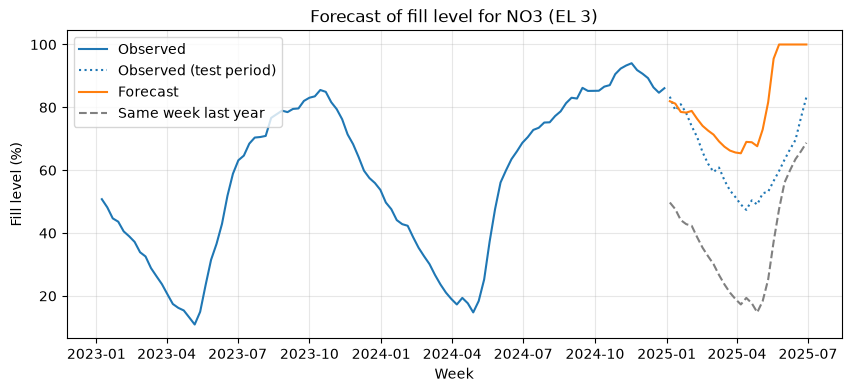

In [13]:
# Trener på 2019–2024 og spår første halvår 2025 (26 uker), uten eksogene variabler
result, mae = forecast_fill_level(data, "2019-01-01", "2024-12-31")
mae_last_year = (result["actual"] - result["last_year"]).abs().mean()
print(f"MAE prognose: {mae:.2f} prosentpoeng")
print(f"MAE samme uke året før: {mae_last_year:.2f} prosentpoeng")

# Plott: de to siste årene før prognosen, de faktiske verdiene, prognosen og fjorårets verdier
history = data["fill_level"].loc[:"2024-12-31"].iloc[-104:]
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(history.index, history, color="tab:blue", label="Observed")
ax.plot(result.index, result["actual"], color="tab:blue", linestyle=":", label="Observed (test period)")
ax.plot(result.index, result["forecast"], color="tab:orange", label="Forecast")
ax.plot(result.index, result["last_year"], color="grey", linestyle="--", label="Same week last year")
ax.set_title("Forecast of fill level for NO3 (EL 3)")
ax.set_xlabel("Week")
ax.set_ylabel("Fill level (%)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

### Test av ulike innstillinger

Funksjonen testes med ulike modeller, eksogene variabler og lengder på historikken. Hver innstilling testes på to perioder (andre halvår 2024 og første halvår 2025), så resultatet ikke avhenger av ett enkelt år. Den beste innstillingen brukes som standard i Streamlit-appen.

In [14]:
# Innstillingene som testes: navn, første uke i treningsdataene og modellparametere
weather_vars = ["precipitation", "snowfall", "temperature_2m"]
settings = [
    ("Last year's value + AR(2)",                    "2019-01-01", dict(p=2, d=0, sd=1, sp=0)),
    ("Weekly change: AR(2) + seasonal AR(1)",        "2019-01-01", dict(p=2, d=1, sd=0, sp=1)),
    ("Weekly change: AR(4) + seasonal AR(1)",        "2019-01-01", dict(p=4, d=1, sd=0, sp=1)),
    ("Weekly change + weather",                      "2019-01-01", dict(p=2, d=1, sd=0, sp=1, exog=weather_vars)),
    ("Weekly change + weather + EUR",                "2019-01-01", dict(p=2, d=1, sd=0, sp=1, exog=weather_vars + ["EUR"])),
    ("Weekly change + weather, short history (3 y)", "2022-01-01", dict(p=2, d=1, sd=0, sp=1, exog=weather_vars)),
    ("Weekly change + weather, long history (9 y)",  "2016-01-01", dict(p=2, d=1, sd=0, sp=1, exog=weather_vars)),
    ("Weekly change + weather, lower learning rate", "2019-01-01", dict(p=2, d=1, sd=0, sp=1, exog=weather_vars, learning_rate=0.001)),
]
# Testperiodene: siste uke i treningsdataene, og navnet på perioden som spås (26 uker)
periods = [("2024-06-30", "H2 2024"), ("2024-12-31", "H1 2025")]

rows = []
for name, train_start, params in settings:
    row = {"Setting": name}
    for train_end, label in periods:
        # ** sender innstillingene i ordboken videre som parametere til funksjonen
        _, mae = forecast_fill_level(data, train_start, train_end, **params)
        row[label] = mae
    rows.append(row)

# Referansen: samme uke året før
row = {"Setting": "Reference: same week last year"}
for train_end, label in periods:
    result, _ = forecast_fill_level(data, "2019-01-01", train_end)
    row[label] = (result["actual"] - result["last_year"]).abs().mean()
rows.append(row)

# Tabell med MAE per periode og gjennomsnittet, sortert med den beste øverst
results = pd.DataFrame(rows).set_index("Setting")
results["Mean"] = results.mean(axis=1)
results.sort_values("Mean").round(2)

,H2 2024,H1 2025,Mean
Setting,,,
"Weekly change + weather, lower learning rate",8.38,8.10,8.24
"Weekly change + weather, short history (3 y)",10.18,7.14,8.66
Weekly change + weather,10.08,8.91,9.50
"Weekly change + weather, long history (9 y)",9.64,9.80,9.72
Weekly change + weather + EUR,11.44,12.74,12.09
Last year's value + AR(2),8.79,16.81,12.80
Weekly change: AR(2) + seasonal AR(1),7.09,19.63,13.36
Weekly change: AR(4) + seasonal AR(1),7.73,21.54,14.63
Reference: same week last year,10.85,26.46,18.66


**Funn:** Den beste innstillingen er en modell som spår den ukentlige endringen i fyllingsgraden (`d=1`), med AR(2), sesong-AR(1) (`sp=1`) og nedbør, snø og temperatur som eksogene variabler, og en lav læringsrate (0,001). Den bommer i gjennomsnitt med 8,2 prosentpoeng, mot 18,7 for referansen (samme uke året før).

Været forbedrer prognosen mest, særlig om våren, fordi snøsmeltingen styrer når magasinene fylles. Valutakursen gjør prognosen dårligere, siden den ikke påvirker hvor mye vann som renner inn i magasinene. Lengden på historikken har liten betydning: tre år ga best resultat for 2025, men ikke for 2024. Modellen som bygger på fjorårets verdi (`sd=1`), bommer mye på våren i år som skiller seg fra året før, slik som 2025.

Den beste innstillingen brukes som standard i Streamlit-appen.

MAE beste modell: 8.10 prosentpoeng


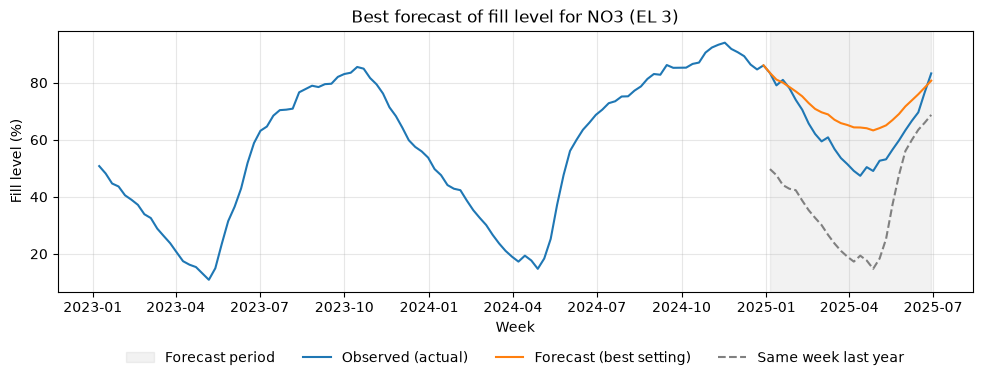

In [15]:
# Den beste innstillingen, testet på første halvår 2025
result, mae = forecast_fill_level(data, "2019-01-01", "2024-12-31", p=2, d=1, sd=0, sp=1,
                                  exog=weather_vars, learning_rate=0.001)
print(f"MAE beste modell: {mae:.2f} prosentpoeng")

# De to siste årene før prognosen og testperioden som én sammenhengende observert linje
observed = data["fill_level"].loc[:result.index[-1]].iloc[-(104 + len(result)):]
# Prognosen starter fra siste observerte uke før testperioden, så linjene henger sammen
start = data["fill_level"].loc[:"2024-12-31"].iloc[-1:]
forecast_line = pd.concat([start, result["forecast"]])

fig, ax = plt.subplots(figsize=(10, 4))
# Grått felt for perioden som spås
ax.axvspan(result.index[0], result.index[-1], color="grey", alpha=0.1, label="Forecast period")
ax.plot(observed.index, observed, color="tab:blue", label="Observed (actual)")
ax.plot(forecast_line.index, forecast_line, color="tab:orange", label="Forecast (best setting)")
ax.plot(result.index, result["last_year"], color="grey", linestyle="--", label="Same week last year")
ax.set_title("Best forecast of fill level for NO3 (EL 3)")
ax.set_xlabel("Week")
ax.set_ylabel("Fill level (%)")
# Forklaringen under plottet, så den ikke dekker dataene
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=4, frameon=False)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()